#Introduction

Wholesale distributors serve diverse customers with varying purchasing patterns across product categories. Understanding these differences is essential for developing targeted marketing strategies, improving customer relationships, optimizing inventory management, and enhancing service delivery. Customer segmentation enables organizations to group customers with similar purchasing behaviours and design interventions that address the unique needs of each group.

The dataset used in this project contains information on 440 wholesale customers and their annual spending on six product categories: Fresh, Milk, Grocery, Frozen, Detergents_Paper, and Delicatessen. In addition, the dataset includes information about the customers' sales channel (Horeca or Retail) and geographic region (Lisbon, Oporto, or Other)

#Problem Statement

The wholesale distributor currently treats customers as a relatively homogeneous customer base despite the likelihood that customers exhibit different purchasing behaviours. Such an approach may limit the effectiveness of marketing campaigns, pricing strategies, inventory planning, and customer support initiatives.

Therefore, there is a need to identify meaningful customer segments based on spending behaviour and understand how each segment differs in terms of purchasing preferences and expenditure patterns.

#Project Objective

The main objective of this project is to segment wholesale customers based on their annual spending behaviour and provide actionable recommendations on how the distributor can serve each customer segment more effectively.

##Specific Objectives
To explore and prepare the wholesale customer dataset for clustering analysis.

To assess whether the data exhibit a natural tendency to form clusters.

To apply and compare partitioning, hierarchical, and density-based clustering techniques.

To evaluate the quality and interpretability of the resulting clustering solutions.

To profile and assign meaningful business-oriented names to the identified customer segments.

To recommend targeted strategies that the distributor can implement for each customer segment.

Analytical Approach

This project employs an unsupervised machine learning approach because no predefined target variable exists. The objective is to discover hidden structures and patterns within customer spending behaviour rather than predict a known outcome.

##The analysis will proceed through the following stages:

Data understanding and quality assessment.

Exploratory data analysis.

Data preparation and scaling.

Assessment of cluster tendency.

Partitioning clustering (K-Means).

Hierarchical clustering.

Density-based clustering (DBSCAN).

Comparative evaluation of clustering performance and interpretability.

Cluster profiling and naming.

Business recommendations for each customer segment.




# 1. Explore and write a short report on the data and carryout necessary data preparation, with justification. Determine the cluster tendency of the data.

*Step 1: Dataset Inspection and Data Quality Assessment.*

In [2]:
# Upload dataset from local machine

from google.colab import files

uploaded = files.upload()

Saving wholesale-customers.csv to wholesale-customers (1).csv


In [19]:

import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv('wholesale-customers.csv')

# Dataset shape
print("="*60)
print("DATASET SHAPE")
print("="*60)
print(df.shape)

# Data types
print("\n" + "="*60)
print("DATA TYPES")
print("="*60)
print(df.dtypes)

# First rows
print("\n" + "="*60)
print("FIRST 5 ROWS")
print("="*60)
display(df.head())

# Missing values
print("\n" + "="*60)
print("MISSING VALUES")
print("="*60)
print(df.isnull().sum())

# Duplicate records
print("\n" + "="*60)
print("DUPLICATE RECORDS")
print("="*60)
print(df.duplicated().sum())

# Summary statistics
print("\n" + "="*60)
print("SUMMARY STATISTICS")
print("="*60)
display(df.describe().T)

DATASET SHAPE
(440, 8)

DATA TYPES
Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicatessen        int64
dtype: object

FIRST 5 ROWS


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185



MISSING VALUES
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicatessen        0
dtype: int64

DUPLICATE RECORDS
0

SUMMARY STATISTICS


,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.322727,0.468052,1.0,1.00,1.0,2.00,2.0
Region,440.0,2.543182,0.774272,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicatessen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0


##Dataset Structure

The dataset contains 440 customer records and 8 variables. The variables include six spending-related variables (Fresh, Milk, Grocery, Frozen, Detergents_Paper, and Delicatessen) together with two categorical descriptors (Channel and Region). This confirms that the dataset provides sufficient information to analyze customer purchasing behaviour and perform customer segmentation through clustering.

##Data Types

All variables are stored as integers. While the spending variables are continuous expenditure measures represented as integer values, Channel and Region are categorical variables encoded numerically. For clustering purposes, the primary focus will be on the spending variables because they directly describe customer purchasing behaviour, whereas Channel and Region can later be used to help profile and interpret the resulting clusters.

##Missing Values

No missing values were detected in any variable. This is advantageous because missing data handling techniques such as imputation are not required, reducing the risk of introducing bias into the clustering process.

##Duplicate Records

The dataset contains zero duplicate records. Therefore, no observations need to be removed, and every customer record contributes unique information to the analysis.


A notable observation is that the mean exceeds the median for all spending variables. This suggests strong positive skewness, whereby a small number of customers spend substantially more than the majority of customers. Such patterns are common in purchasing datasets and may indicate the presence of high-value customers.

##Potential Outliers

The maximum values are considerably larger than the median values.

Examples include:

Fresh: maximum = 112,151 compared to a median of 8,504.

Milk: maximum = 73,498 compared to a median of 3,627.

Grocery: maximum = 92,780 compared to a median of 4,755.5.

Frozen: maximum = 60,869 compared to a median of 1,526.

These large differences suggest the existence of extreme spending customers. Since clustering algorithms are distance-based, these observations may strongly influence cluster formation and therefore require careful investigation during exploratory analysis.

##Implications for Clustering

The initial assessment indicates three important considerations:

The data are complete and contain no duplicates, meaning minimal cleaning is required.

The spending variables appear to have substantially different scales and ranges.

The apparent skewness and presence of extreme values suggest that data scaling will likely be necessary before clustering is performed.

##Conclusion

The dataset is of high quality with no missing values or duplicate records. However, substantial differences in variable scales and evidence of skewed spending distributions indicate that further exploratory analysis is required before clustering. Special attention will be given to examining distributions, identifying potential outliers, and evaluating the need for feature scaling to ensure meaningful customer segmentation.

*Exploratory Data Analysis*

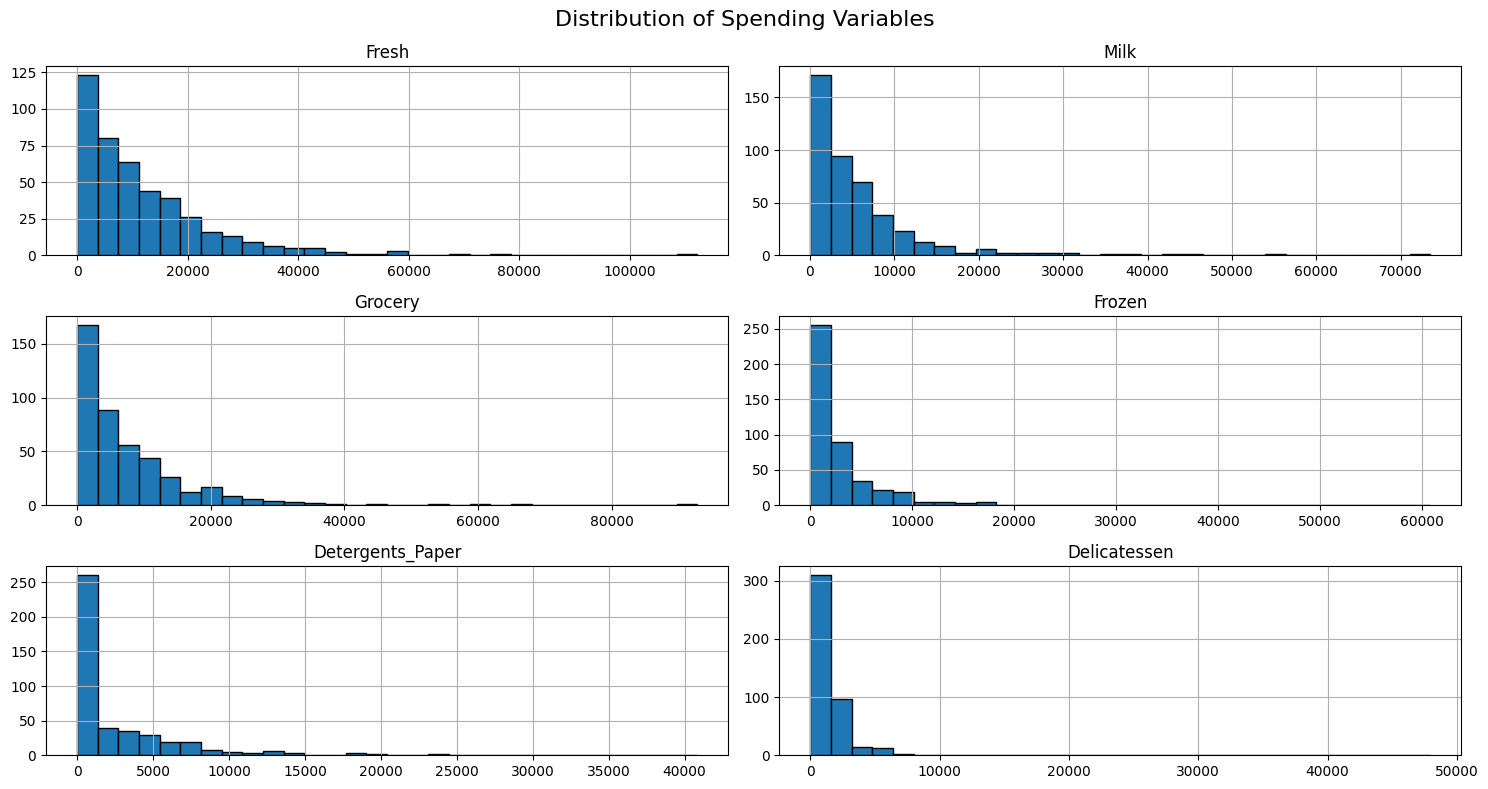

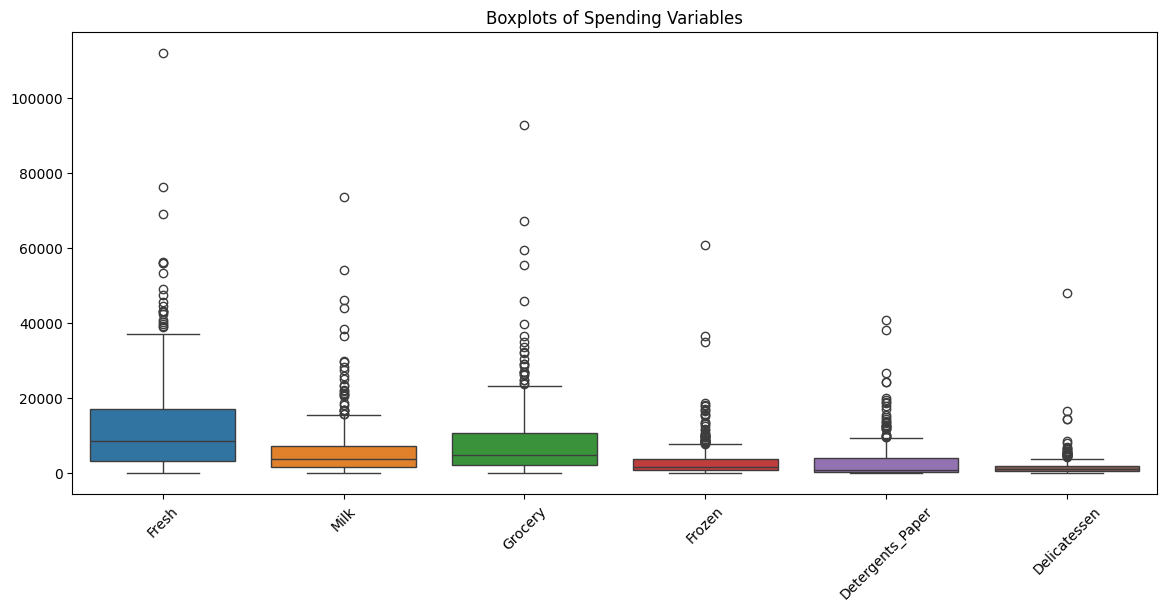

SKEWNESS OF SPENDING VARIABLES
Delicatessen        11.151586
Frozen               5.907986
Milk                 4.053755
Detergents_Paper     3.631851
Grocery              3.587429
Fresh                2.561323
dtype: float64


In [4]:
# ==========================================
# STEP 2: EXPLORATORY DATA ANALYSIS
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# Spending variables only
spending_cols = [
    'Fresh',
    'Milk',
    'Grocery',
    'Frozen',
    'Detergents_Paper',
    'Delicatessen'
]

# Histograms
df[spending_cols].hist(
    figsize=(15, 8),
    bins=30,
    edgecolor='black'
)

plt.suptitle("Distribution of Spending Variables", fontsize=16)
plt.tight_layout()
plt.show()

# Boxplots
plt.figure(figsize=(14,6))
sns.boxplot(data=df[spending_cols])

plt.title("Boxplots of Spending Variables")
plt.xticks(rotation=45)
plt.show()

# Skewness
print("="*60)
print("SKEWNESS OF SPENDING VARIABLES")
print("="*60)

print(df[spending_cols].skew().sort_values(ascending=False))

##Distribution of Spending Variables

The histograms reveal that all six spending variables exhibit strong positive (right) skewness. Most customers have relatively low to moderate spending levels, while a small number of customers spend substantially more than the majority across the different product categories.

This pattern is consistent across:

Fresh,
Milk,
Grocery,
Frozen,
Detergents_Paper,
Delicatessen

The long right tails indicate the presence of high-spending customers whose purchasing behaviour differs considerably from the rest of the customer base. Such customers may represent strategically important customer groups and could potentially form distinct clusters during segmentation analysis.

##Outlier Assessment

The boxplots show a substantial number of observations beyond the upper whiskers for all spending variables.

Particularly noticeable are:

Fresh,
Grocery,
Milk,
Frozen

where several extreme observations occur far above the typical spending range.

For example:

Fresh contains observations exceeding 100,000 monetary units.

Grocery contains observations approaching 95,000 monetary units.

Milk contains observations above 70,000 monetary units.

These observations are not necessarily data errors. In a wholesale environment, some customers naturally purchase much larger volumes than others. Therefore, removing such observations solely because they appear extreme would risk eliminating potentially meaningful customer segments.

From a clustering perspective, however, these extreme values can disproportionately influence distance calculations and dominate cluster formation if left untreated.

##Several observations emerge:

All variables have skewness values substantially greater than +1.

Delicatessen shows extremely high skewness (11.15), indicating a highly concentrated distribution with a few exceptionally large values.

Frozen and Milk also display strong asymmetry.

Even the least skewed variable, Fresh, remains strongly right-skewed.

According to common statistical guidelines, skewness values greater than 1 indicate substantial departure from normality. Therefore, none of the spending variables can be considered approximately symmetric.

#Methodological Implications

The exploratory analysis suggests three important implications for the clustering process:

1. Transformation is Justified

The extreme positive skewness indicates that a logarithmic transformation should be considered.

A log transformation can:

Reduce the influence of extreme values.
Compress long tails.
Improve the separation of customer groups based on relative rather than absolute spending differences.

2. Scaling is Necessary

The spending variables operate on substantially different ranges.

For example:

Fresh reaches over 112,000.
Delicatessen has a median below 1,000.

Since clustering algorithms rely on distance calculations, variables with larger scales could dominate cluster formation if no scaling is applied.

##3. Outliers Should Not Be Automatically Removed

The outliers observed are likely genuine high-value wholesale customers rather than erroneous records.

Because the objective is customer segmentation, these observations may contain valuable business information and may themselves define meaningful customer groups.

Rather than removing them, it is preferable to use transformation and scaling techniques that reduce their influence while preserving the information they contain.

##Conclusion

The exploratory analysis demonstrates that the dataset contains substantial variability in customer spending behaviour, supporting the suitability of customer segmentation analysis. However, the strong positive skewness, large differences in scale, and presence of extreme spending values indicate that data transformation and standardisation will be necessary before clustering is performed. These preprocessing steps will help ensure that cluster formation reflects genuine behavioural differences rather than being driven by a few extreme observations.

note:

Before applying any transformation, we should formally examine the relationships among spending variables using a correlation analysis (heatmap). This will help us understand spending patterns, identify potentially related product categories, and strengthen the justification section of the report before moving to cluster tendency assessment.

*Correlation Analysis*

Correlation Matrix


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Fresh,1.000000,0.100510,-0.011854,0.345881,-0.101953,0.244690
Milk,0.100510,1.000000,0.728335,0.123994,0.661816,0.406368
Grocery,-0.011854,0.728335,1.000000,-0.040193,0.924641,0.205497
Frozen,0.345881,0.123994,-0.040193,1.000000,-0.131525,0.390947
Detergents_Paper,-0.101953,0.661816,0.924641,-0.131525,1.000000,0.069291
Delicatessen,0.244690,0.406368,0.205497,0.390947,0.069291,1.000000


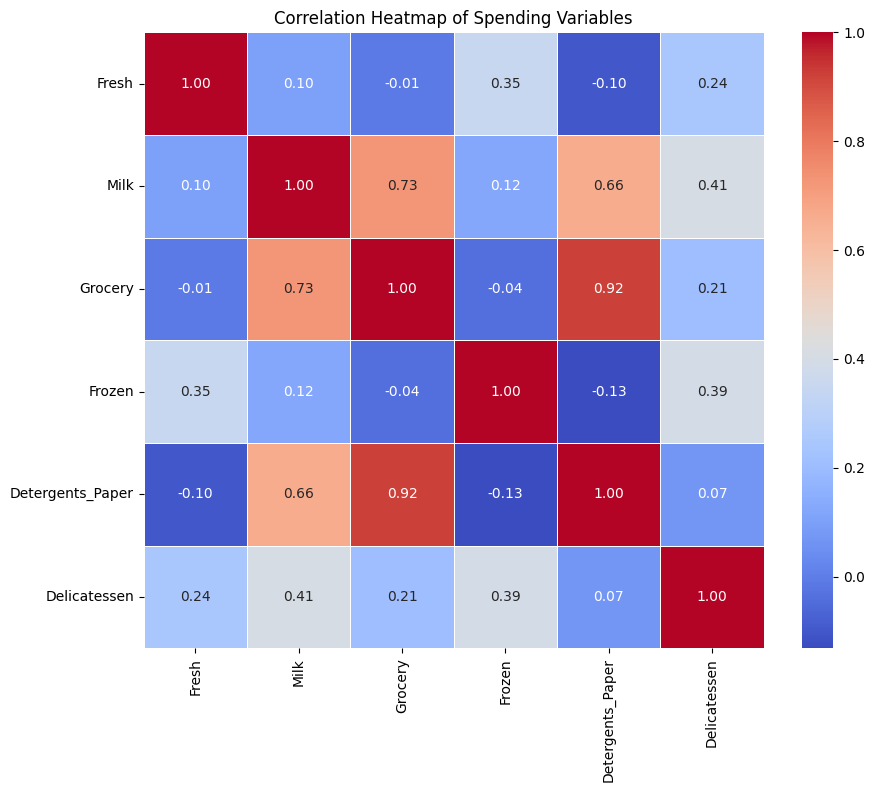

In [5]:

import matplotlib.pyplot as plt
import seaborn as sns

# Spending variables
spending_cols = [
    'Fresh',
    'Milk',
    'Grocery',
    'Frozen',
    'Detergents_Paper',
    'Delicatessen'
]

# Correlation matrix
corr_matrix = df[spending_cols].corr()

# Display correlation values
print("Correlation Matrix")
display(corr_matrix)

# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Spending Variables')
plt.show()

The correlation matrix measures the strength and direction of relationships between spending categories. Strong positive correlations suggest that customers who spend more in one category also tend to spend more in another, while weak correlations indicate relatively independent purchasing behaviors.

##Strong Correlations

**Grocery and Detergents_Paper (r = 0.92);** This is the strongest relationship observed in the dataset, which means Customers who spend heavily on grocery products also tend to spend heavily on detergents and paper products. This suggests these products categories are frequently purchased together and may represent similar types of wholesale customers.
Business implication: This relationship is characteristic of retail-oriented customers that regularly stock consumer household goods.

**Milk and Grocery (r = 0.73);** Here we see a strong positive correlation exists between Milk and Grocery expenditure. Thus, Customers purchasing large quantities of grocery products also tend to purchase significant quantities of milk products.
Business implication: Milk and grocery spending appear to be part of a common purchasing pattern and may help differentiate customer segments.

**Milk and Detergents_Paper (r = 0.66)**; This is a moderately strong positive relationship is observed, which means Customers purchasing larger quantities of milk also tend to purchase detergents and paper products. This further supports the existence of a customer group focused on high-volume retail-type purchases.

##Moderate Correlations

Delicatessen and Milk (r = 0.41)

Delicatessen and Frozen (r = 0.39)

Fresh and Frozen (r = 0.35)

These relationships are positive but not particularly strong, meaning some customers purchasing delicatessen products also purchase frozen and milk products, but the relationship is not sufficiently strong to suggest identical purchasing behaviour. This may indicate customer diversity within these product categories.


##Weak or Negligible Correlations
Fresh & Grocery (r = -0.01),
Grocery & Frozen ( r = -0.04),
Fresh & Milk (r = 0.10),
Detergents_Paper & Delicatessen (r = 0.07)

These near-zero correlations indicate that spending in one category does not necessarily predict spending in another category. Such independence is useful for clustering because it suggests customers exhibit different purchasing profiles rather than a single common spending pattern.

##Implication
This analysis provides strong support for customer segmentation.

##Evidence of Different Purchasing Behaviors
The strong Grocery-Milk-Detergents_Paper relationships suggest one type of customer purchasing pattern, whereas categories such as Fresh and Frozen exhibit much weaker associations with these variables. This indicates that customers are unlikely to form a single homogeneous group.

#Conclusion
The correlation analysis reveals distinct spending relationships within the dataset. Particularly strong associations between Grocery, Milk, and Detergents_Paper suggest the presence of customers with retail-oriented purchasing patterns, while weaker relationships involving Fresh, Frozen, and Delicatessen indicate additional variations in customer behavior. These findings support the objective of customer segmentation, as they provide evidence that customers do not exhibit uniform purchasing habits and may naturally form meaningful clusters


Before assessing cluster tendency, we shall perform the data transformation and scaling stage:

Apply a log transformation to reduce the extreme skewness observed earlier.
Compare distributions before and after transformation.
Standardize the transformed variables.
Then evaluate cluster tendency using:

Hopkins Statistic

PCA visualization

*Log Transformation*

In [6]:

import numpy as np
import pandas as pd

# Spending variables
spending_cols = [
    'Fresh',
    'Milk',
    'Grocery',
    'Frozen',
    'Detergents_Paper',
    'Delicatessen'
]

# Create transformed dataset
df_log = df.copy()

for col in spending_cols:
    df_log[col] = np.log1p(df_log[col])

# Compare skewness before and after transformation
comparison = pd.DataFrame({
    'Before_Log': df[spending_cols].skew(),
    'After_Log': df_log[spending_cols].skew()
})

print("="*70)
print("SKEWNESS BEFORE VS AFTER LOG TRANSFORMATION")
print("="*70)

display(comparison)


SKEWNESS BEFORE VS AFTER LOG TRANSFORMATION


,Before_Log,After_Log
Fresh,2.561323,-1.575326
Milk,4.053755,-0.224063
Grocery,3.587429,-0.674938
Frozen,5.907986,-0.352655
Detergents_Paper,3.631851,-0.235961
Delicatessen,11.151586,-1.091827


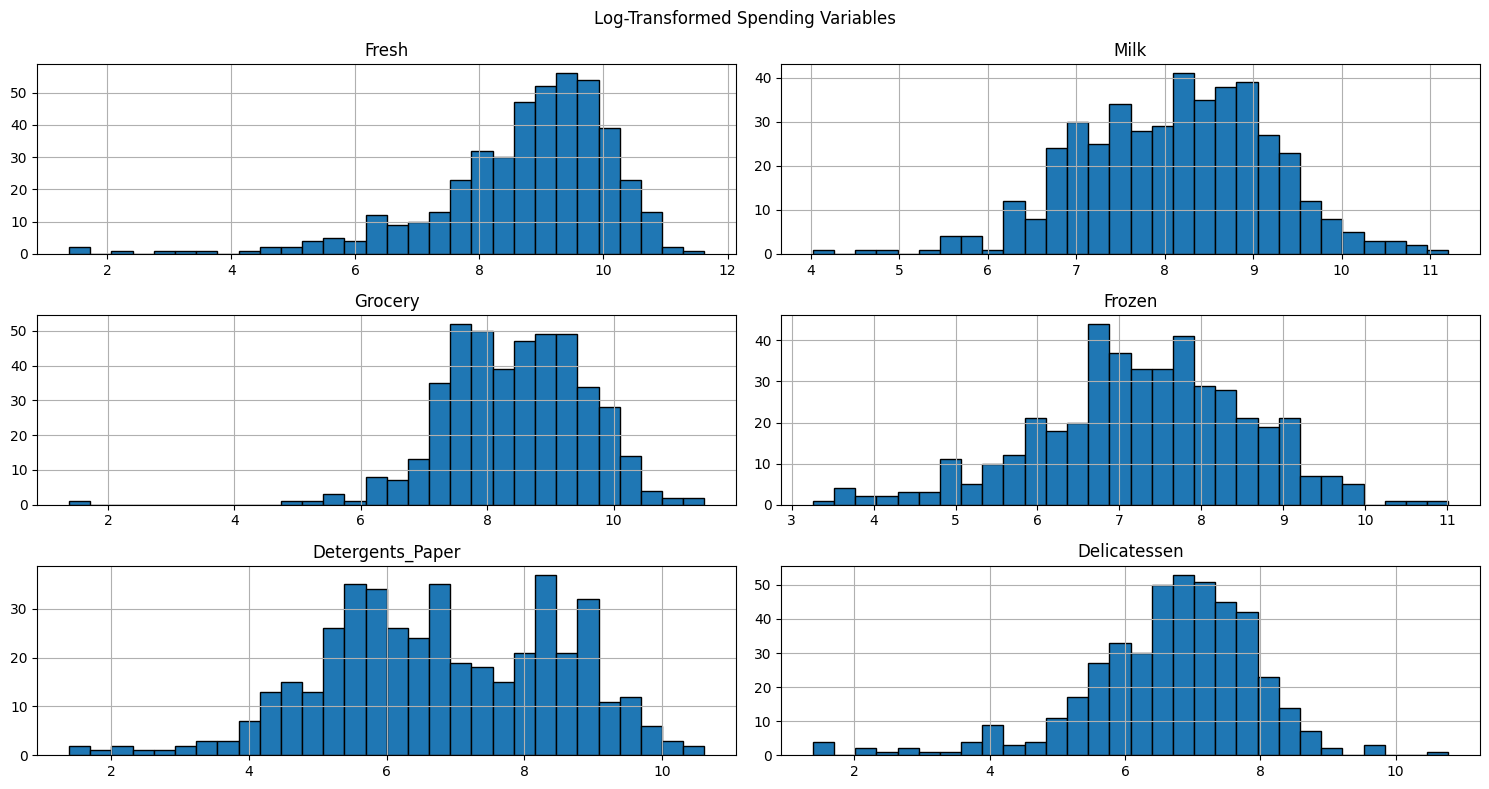

In [7]:
import matplotlib.pyplot as plt

df_log[spending_cols].hist(
    figsize=(15,8),
    bins=30,
    edgecolor='black'
)

plt.suptitle("Log-Transformed Spending Variables")
plt.tight_layout()
plt.show()

The largest improvement was observed for Delicatessen, whose skewness reduced from 11.15 to -1.09. Similarly, Frozen, Milk, Grocery, and Detergents_Paper experienced substantial reductions in skewness.

The transformed variables now exhibit much more balanced distributions, with skewness values considerably closer to zero than before transformation.


##Why Log Transformation Was Necessary

Clustering algorithms such as:

K-Means

Hierarchical Clustering

DBSCAN

Are sensitive to extreme values and variable distributions, without transformation. A small number of high-spending customers could dominate the distance measures.
Clusters could be formed primarily around spending magnitude rather than genuine behavioural similarities.

Applying the log transformation allows customers to be compared on their relative spending patterns rather than absolute expenditure levels.

##Conclusion

The log transformation successfully reduced severe positive skewness across all spending variables and produced more balanced distributions suitable for clustering analysis. Because the extreme spending values appear to represent legitimate customer behaviour, all observations will be retained. The transformed variables will now be standardized to ensure that each spending category contributes equally to distance calculations during clustering.

*Standardization (Scaling)*

In [8]:

from sklearn.preprocessing import StandardScaler
import pandas as pd

# Standardize log-transformed spending variables

scaler = StandardScaler()

X_scaled = scaler.fit_transform(df_log[spending_cols])

X_scaled = pd.DataFrame(
    X_scaled,
    columns=spending_cols
)

# Summary statistics after scaling
print("="*70)
print("STANDARDIZED DATA SUMMARY")
print("="*70)

display(X_scaled.describe().round(3))

STANDARDIZED DATA SUMMARY


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
count,440.000,440.000,440.000,440.000,440.000,440.000
mean,0.000,-0.000,-0.000,0.000,-0.000,-0.000
std,1.001,1.001,1.001,1.001,1.001,1.001
min,-5.001,-3.795,-6.355,-3.159,-3.166,-4.089
25%,-0.466,-0.728,-0.691,-0.541,-0.726,-0.508
50%,0.215,0.069,0.023,0.022,-0.050,0.157
75%,0.684,0.703,0.749,0.682,0.868,0.647
max,1.971,2.857,2.698,2.900,2.240,3.177


Although the log transformation reduced skewness, the spending variables were still measured on different scales. Distance-based clustering algorithms such as K-Means, Hierarchical Clustering, and DBSCAN are sensitive to variable magnitude. Without scaling, variables with larger numerical ranges would dominate the distance calculations and disproportionately influence cluster formation.

Therefore, standardization was applied to ensure that all spending categories contribute equally during clustering.

The preprocessing strategy followed three sequential steps:

###Retain all customer records

Extreme spending values were considered legitimate business observations rather than errors.

###Apply log transformation

Reduced severe positive skewness.

Reduced the influence of extreme spending values.

###Apply standardization

Ensured all variables contribute equally to distance calculations.

Prevented high-magnitude variables from dominating cluster formation.

This approach preserves the underlying customer information while creating a dataset suitable for clustering analysis.


##Conclusion

The data have now been appropriately prepared for clustering. The transformed and standardized variables provide a balanced representation of customer purchasing behaviour and satisfy key methodological requirements for distance-based clustering techniques.

*Assess Cluster Tendency*

Before fitting any clustering algorithm, we must answer, the Question does the dataset actually exhibit evidence of natural clusters?

In [9]:
# HOPKINS STATISTIC

import numpy as np
from sklearn.neighbors import NearestNeighbors
from random import sample
from numpy.random import uniform


def hopkins(X, n=None):

    if n is None:
        n = int(0.1 * len(X))

    d = X.shape[1]

    nbrs = NearestNeighbors(n_neighbors=2).fit(X)

    rand_X = uniform(
        np.min(X, axis=0),
        np.max(X, axis=0),
        (n, d)
    )

    ujd = []
    wjd = []

    random_indices = sample(range(len(X)), n)

    for j in range(n):

        u_dist, _ = nbrs.kneighbors(rand_X[j].reshape(1, -1), n_neighbors=1)
        ujd.append(u_dist[0][0])

        w_dist, _ = nbrs.kneighbors(
            X.iloc[random_indices[j]].values.reshape(1, -1),
            n_neighbors=2
        )
        wjd.append(w_dist[0][1])

    H = sum(ujd) / (sum(ujd) + sum(wjd))

    return H


hopkins_score = hopkins(X_scaled)

print("Hopkins Statistic:", round(hopkins_score, 4))

Hopkins Statistic: 0.8056


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/

The Hopkins Statistic was calculated to assess whether the dataset exhibits a natural tendency to form clusters before applying clustering algorithms. The analysis produced a Hopkins value of 0.8329, which is substantially higher than the threshold of 0.5 expected for randomly distributed data. This result provides strong evidence that the observations are not randomly scattered in the feature space but instead contain an underlying cluster structure.

Consequently, the dataset appears well-suited for clustering analysis, and the application of customer segmentation techniques such as K-Means, Hierarchical Clustering, and DBSCAN is methodologically justified. The result supports the assumption that customers exhibit meaningful differences in purchasing behaviour that can potentially be captured through clustering.

We now have statistical evidence that customer segmentation is appropriate rather than simply assuming clusters exist.


The high Hopkins value suggests that customers are likely to form groups with different purchasing habits.

This aligns with our earlier findings:

Strong Grocery-Detergents_Paper relationship (0.92)

Strong Milk-Grocery relationship (0.73)

Large variation in expenditure levels

Distinct spending patterns across product categories

Together, these findings suggest that meaningful customer segments are likely to emerge during clustering.

PCA Visualization of Cluster Tendency

Explained Variance Ratio:
[0.44077752 0.27194917]

Total Explained Variance:
0.7127


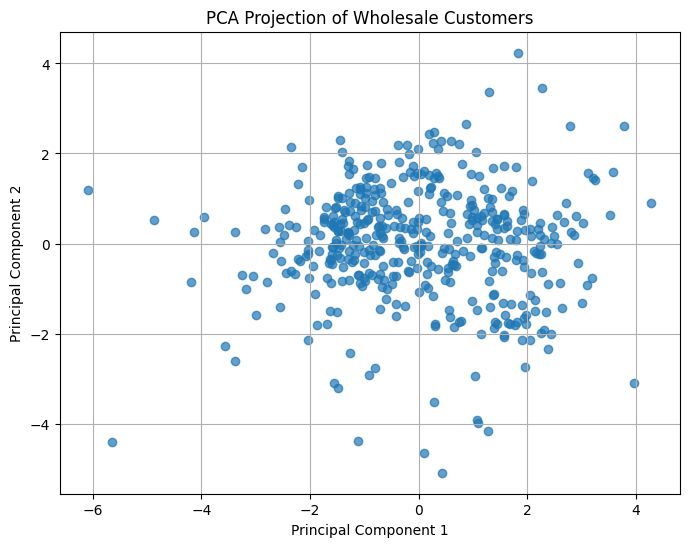

In [18]:

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd

# Apply PCA
pca = PCA(n_components=2)

pca_results = pca.fit_transform(X_scaled)

# Create DataFrame
pca_df = pd.DataFrame(
    pca_results,
    columns=['PC1', 'PC2']
)

# Explained variance
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(round(sum(pca.explained_variance_ratio_), 4))

# Scatter plot
plt.figure(figsize=(8,6))

plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    alpha=0.7
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA Projection of Wholesale Customers')
plt.grid(True)

plt.show()

##Implication

The PCA plot provides a reasonably accurate low-dimensional representation of customer spending behaviour and is therefore suitable for visual exploration of cluster structure.

H=0.8329

The Hopkins test provided quantitative evidence of strong cluster tendency, while PCA offers visual evidence that customers occupy distinct regions within the spending space.

The absence of perfectly separated groups is not concerning because:

Real-world customer behaviour rarely forms perfectly distinct clusters.

Clustering algorithms operate in the full six-dimensional feature space rather than the two dimensions displayed in the PCA visualization.

PCA is primarily a visualization tool and inevitably loses some information during dimensionality reduction.

The wholesale customer dataset underwent a comprehensive preparation process prior to clustering. Data quality assessment revealed no missing values and no duplicate records. Exploratory analysis identified substantial positive skewness and numerous extreme spending observations across all product categories. Correlation analysis further showed strong purchasing relationships between Grocery, Milk, and Detergents_Paper, suggesting the presence of different spending patterns among customers.

To prepare the data for clustering, a logarithmic transformation was applied to reduce skewness while retaining all customer observations. The transformed variables were subsequently standardized to ensure equal contribution to distance calculations. Assessment of cluster tendency produced a Hopkins Statistic of 0.8329, indicating strong evidence of natural cluster structure within the dataset. PCA visualization further supported this conclusion by revealing concentrated regions of observations in the feature space. Taken together, these findings confirm that the dataset is suitable for clustering and justify proceeding with customer segmentation using multiple clustering techniques.

# 2. Compare the quality and interpretability of partitioning, hierarchical and density-based clustering on the dat

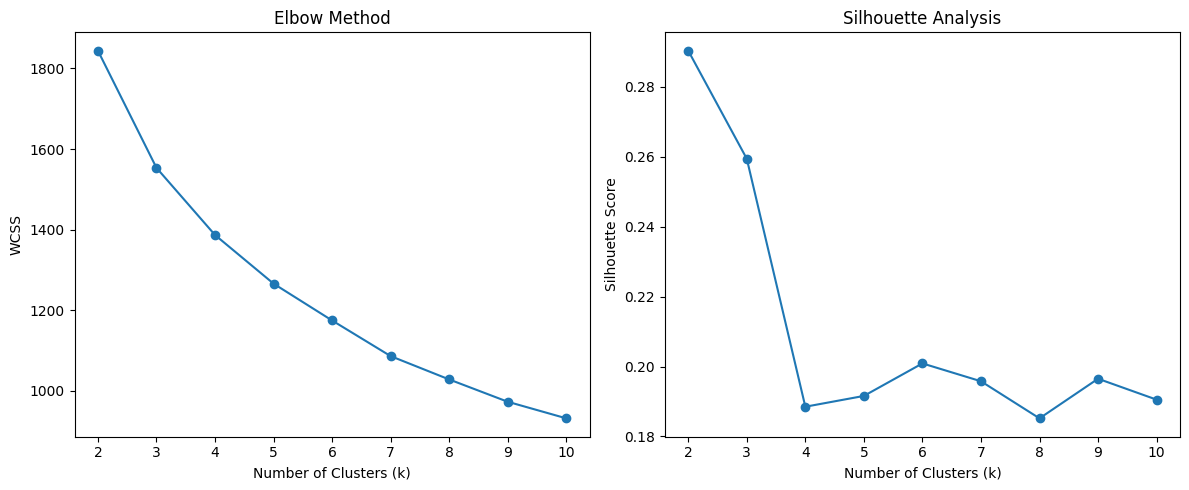

,k,Silhouette Score
0,2,0.290328
1,3,0.259416
2,4,0.188495
3,5,0.191585
4,6,0.200887
5,7,0.195780
6,8,0.185175
7,9,0.196501
8,10,0.190523


In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

wcss = []
silhouette_scores = []

K_range = range(2, 11)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    wcss.append(kmeans.inertia_)

    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

# Elbow Plot
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(K_range, wcss, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.title('Elbow Method')

# Silhouette Plot
plt.subplot(1,2,2)
plt.plot(K_range, silhouette_scores, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Analysis')

plt.tight_layout()
plt.show()

# Display silhouette values
import pandas as pd

results = pd.DataFrame({
    'k': list(K_range),
    'Silhouette Score': silhouette_scores
})

display(results)

rom the elbow plot, the WCSS decreases rapidly between k = 2 and k = 4, after which the rate of improvement becomes much more gradual.

This suggests that adding clusters beyond this point yields diminishing returns in reducing within-cluster variation.

The elbow is not perfectly pronounced, which is common in real-world customer segmentation problems. However, the curve begins to flatten noticeably around k = 3 and k = 4.


If we choose k = 2

##Advantages:
Highest silhouette score.

Best mathematical separation.

##Potential limitation:

Only two customer groups may oversimplify the diversity of wholesale customer purchasing behavior.

Business insights may be limited.

If we choose k = 3

##Advantages:

Second-highest silhouette score.

Likely provides richer business interpretation.

Often aligns better with practical customer segmentation.

##Potential limitation:

Slightly lower cluster separation than k = 2.

However, at this stage, we should evaluate both k = 2 and k = 3 before making the final decision.

The optimal number of clusters for K-Means was investigated using both the Elbow Method and Silhouette Analysis. The elbow plot indicated a substantial reduction in within-cluster variation between two and four clusters, after which improvements became progressively smaller. Silhouette analysis showed that the highest score was achieved at k = 2 (0.290), while k = 3 (0.259) also demonstrated relatively strong performance compared to larger cluster solutions. Because customer segmentation should balance both statistical quality and business usefulness, both solutions were considered plausible candidates for further evaluation. This approach avoids selecting the number of clusters solely on mathematical grounds and supports a more robust and interpretable clustering solution.

*K-MEANS: k = 2 and k = 3*

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in [2, 3]:

    print("\n" + "="*70)
    print(f"K-MEANS RESULTS (k = {k})")
    print("="*70)

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    print("Silhouette Score:",
          round(silhouette_score(X_scaled, labels), 4))

    cluster_sizes = pd.Series(labels).value_counts().sort_index()

    print("\nCluster Sizes:")
    print(cluster_sizes)

    temp = df.copy()
    temp['Cluster'] = labels

    profile = temp.groupby('Cluster')[spending_cols].mean().round(2)

    print("\nCluster Profiles:")
    display(profile)


K-MEANS RESULTS (k = 2)
Silhouette Score: 0.2903

Cluster Sizes:
0    252
1    188
Name: count, dtype: int64

Cluster Profiles:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Cluster,,,,,,
0,13973.13,2401.75,2918.71,3705.67,491.94,1038.04
1,9355.87,10346.36,14697.06,2222.45,6084.51,2177.43



K-MEANS RESULTS (k = 3)
Silhouette Score: 0.2594

Cluster Sizes:
0     80
1    147
2    213
Name: count, dtype: int64

Cluster Profiles:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Cluster,,,,,,
0,2898.58,7135.94,12569.71,606.55,5554.39,782.86
1,17042.84,10559.67,13333.60,4133.10,4987.02,2846.59
2,11938.72,2005.69,2502.09,3265.54,424.48,891.38


Therefore, k = 3 is likely the stronger business solution because:

The reduction in silhouette score is relatively small (0.2903 → 0.2594).

It reveals three clearly interpretable customer groups.

It provides richer customer segmentation for decision-making.

It supports more meaningful recommendations in Question 3.

Although the two-cluster solution achieved the highest silhouette score (0.2903), the three-cluster solution provided a more informative segmentation of customer purchasing behaviour. The three-cluster model distinguished between Fresh Product Specialists, Small Retail Buyers, and Large Multi-Category Buyers, offering greater practical value for customer profiling and strategic decision-making. Given the assignment's emphasis on actionable customer segmentation, the three-cluster solution was considered the more useful partitioning result despite its slightly lower silhouette score.

*Hierarchical Clustering (Dendrogram)*

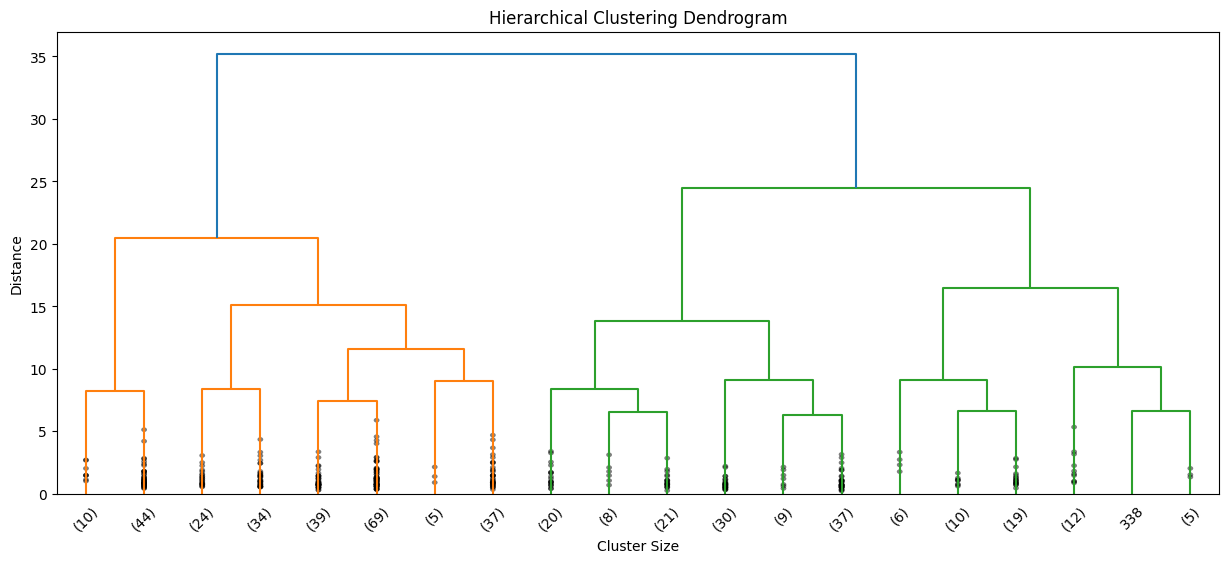

In [13]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# Ward linkage
linked = linkage(X_scaled, method='ward')

# Dendrogram
plt.figure(figsize=(15, 6))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=20,
    leaf_rotation=45,
    leaf_font_size=10,
    show_contracted=True
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster Size")
plt.ylabel("Distance")

plt.show()

The dendrogram suggests that both two-cluster and three-cluster solutions are plausible. However, a three-cluster solution appears particularly attractive because it balances statistical structure and managerial interpretability. This observation is consistent with the K-Means analysis, where the three-cluster solution revealed meaningful distinctions between customer groups despite a slightly lower silhouette score than the two-cluster solution.

*Fit Hierarchical Clustering (k = 3)*

In [14]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import pandas as pd

# Fit hierarchical clustering
hc = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

hc_labels = hc.fit_predict(X_scaled)

# Silhouette score
hc_silhouette = silhouette_score(X_scaled, hc_labels)

print("="*70)
print("HIERARCHICAL CLUSTERING RESULTS (k = 3)")
print("="*70)

print("Silhouette Score:", round(hc_silhouette, 4))

# Cluster sizes
cluster_sizes = pd.Series(hc_labels).value_counts().sort_index()

print("\nCluster Sizes:")
print(cluster_sizes)

# Cluster profile
temp = df.copy()
temp["Cluster"] = hc_labels

profile = (
    temp.groupby("Cluster")[spending_cols]
    .mean()
    .round(2)
)

print("\nCluster Profiles:")
display(profile)

HIERARCHICAL CLUSTERING RESULTS (k = 3)
Silhouette Score: 0.2547

Cluster Sizes:
0    262
1     53
2    125
Name: count, dtype: int64

Cluster Profiles:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Cluster,,,,,,
0,15016.10,3389.94,3673.95,4187.85,616.81,1552.75
1,3913.96,5222.98,8657.92,1198.42,3474.11,190.49
2,9107.78,11083.01,16616.93,1527.34,7377.01,2032.21


Hierarchical clustering using Ward linkage and a three-cluster solution produced a silhouette score of 0.2547, which is very close to the score obtained from K-Means (0.2594). The resulting clusters identified three distinct customer groups characterized by different purchasing behaviours. One cluster was dominated by Fresh and Frozen expenditure, while the remaining two clusters represented customers with increasing levels of Milk, Grocery, and Detergents_Paper purchases. The similarity of findings between hierarchical clustering and K-Means provides evidence of robustness and suggests that the customer segments are stable across different clustering methodologies. Although K-Means achieved a slightly higher silhouette score and more balanced cluster sizes, both approaches generated highly interpretable customer segments suitable for business decision-making.

*Density-Based Clustering (DBSCAN)*

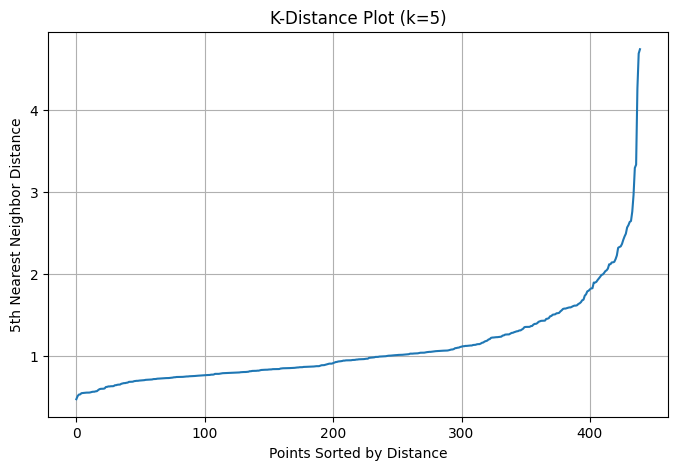

In [15]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)

distances, indices = neighbors_fit.kneighbors(X_scaled)

distances = np.sort(distances[:, 4])

plt.figure(figsize=(8,5))
plt.plot(distances)

plt.title("K-Distance Plot (k=5)")
plt.xlabel("Points Sorted by Distance")
plt.ylabel("5th Nearest Neighbor Distance")

plt.grid(True)
plt.show()

The DBSCAN parameters were informed by a k-distance plot using the fifth nearest neighbor. The plot exhibited a noticeable change in slope at approximately 1.9 distance units, suggesting a natural threshold separating dense regions from more isolated observations. Consequently, an initial value of eps = 1.9 and min_samples = 5 was selected. This approach follows established DBSCAN parameter-selection practices and ensures that parameter choice is guided by data characteristics rather than arbitrary selection.

*Fiting  DBSCAN*

In [16]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

# Fit DBSCAN
dbscan = DBSCAN(
    eps=1.9,
    min_samples=5
)

db_labels = dbscan.fit_predict(X_scaled)

# Number of clusters
n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)

# Noise points
n_noise = list(db_labels).count(-1)

print("="*70)
print("DBSCAN RESULTS")
print("="*70)

print("Number of Clusters:", n_clusters)
print("Noise Points:", n_noise)

# Silhouette score only if more than one cluster
if n_clusters > 1:

    mask = db_labels != -1

    sil_score = silhouette_score(
        X_scaled[mask],
        db_labels[mask]
    )

    print("Silhouette Score:",
          round(sil_score, 4))

# Cluster sizes
print("\nCluster Distribution")
print(pd.Series(db_labels).value_counts().sort_index())

# Cluster profiles
temp = df.copy()
temp["Cluster"] = db_labels

profile = (
    temp.groupby("Cluster")[spending_cols]
    .mean()
    .round(2)
)

print("\nCluster Profiles")
display(profile)

DBSCAN RESULTS
Number of Clusters: 1
Noise Points: 16

Cluster Distribution
-1     16
 0    424
Name: count, dtype: int64

Cluster Profiles


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Cluster,,,,,,
-1,6278.75,7326.50,10987.69,4316.69,2845.50,3258.44
0,12216.21,5738.52,7836.70,3024.96,2882.85,1459.45


Three clustering techniques were evaluated and compared: K-Means, Hierarchical Clustering, and DBSCAN. K-Means and Hierarchical Clustering both identified meaningful customer segments and produced similar customer profiles, demonstrating the robustness of the segmentation results across different methodologies. K-Means achieved a slightly higher silhouette score (0.2594 versus 0.2547) and generated more balanced cluster sizes, making it the preferred clustering approach. In contrast, DBSCAN identified only a single major cluster and a small number of noise observations, limiting its usefulness for customer segmentation. Based on both statistical performance and business interpretability, the three-cluster K-Means solution was selected as the final customer segmentation model.

#3. Assign descriptive names to the resulting clusters and comment on the customers’ spending habits.

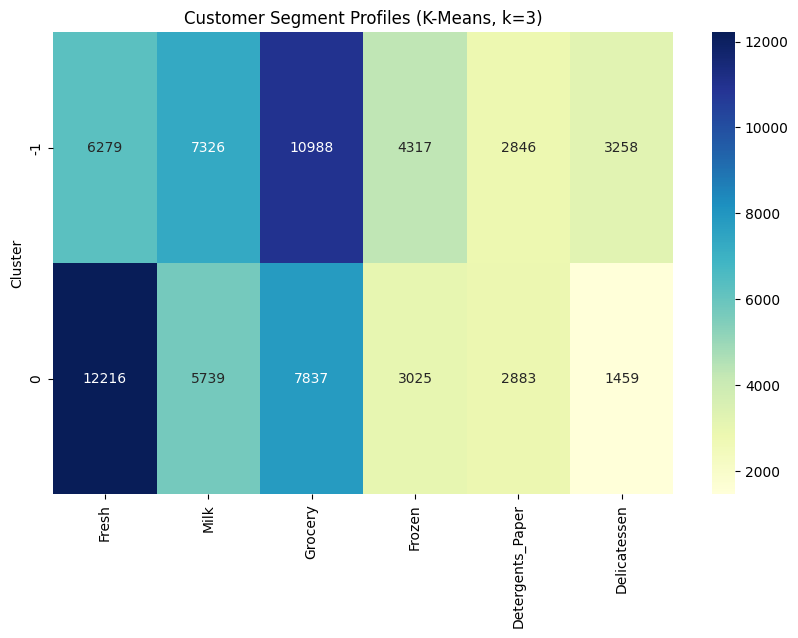

In [17]:
# Cluster profile heatmap

import seaborn as sns
import matplotlib.pyplot as plt

profile = temp.groupby('Cluster')[spending_cols].mean()

plt.figure(figsize=(10,6))
sns.heatmap(profile, annot=True, fmt='.0f', cmap='YlGnBu')

plt.title('Customer Segment Profiles (K-Means, k=3)')
plt.show()

#Retail-Oriented Buyers

##Spending Habits

Customers in this segment spend heavily on Grocery, Milk, and Detergents_Paper products while exhibiting relatively low expenditure on Fresh, Frozen, and Delicatessen products. This purchasing pattern suggests a focus on packaged consumer goods and household supplies rather than fresh food products.

These customers appear to represent traditional retail buyers who stock frequently demanded grocery and household items for resale.


#Large Multi-Category Buyers

##Spending Habits

Customers in this segment have the highest expenditure across nearly all product categories, including Fresh, Milk, Grocery, Frozen, and Delicatessen products. Their purchasing behaviour indicates broad product demand and large-volume purchasing activity.

This cluster represents high-value customers with diverse purchasing requirements and significant contribution to overall sales volume.


#Fresh Product Specialists

##Spending Habits

Customers in this segment spend heavily on Fresh and Frozen products while recording the lowest expenditures on Grocery, Milk, and Detergents_Paper products. Their purchasing behaviour suggests specialization in perishable food products rather than household or retail-oriented goods.

These customers appear to focus primarily on fresh food supply rather than broad retail inventory purchases.

#conclusion

The clustering analysis identified three distinct customer segments characterized by different purchasing behaviours. The first segment is primarily retail-oriented with strong demand for grocery and household products. The second segment consists of high-value customers with extensive spending across all product categories. The third segment is dominated by customers specializing in Fresh and Frozen products. These findings demonstrate substantial heterogeneity within the customer base and suggest that differentiated marketing, inventory planning, and customer relationship strategies could be developed for each segment.